This demonstration draws on a [scikit-learn example](https://scikit-learn.org/stable/auto_examples/neighbors/plot_lof_outlier_detection.html).

In [1]:
%matplotlib inline

# Local Outlier Factor (LOF)

The [local outlier factor](https://scikit-learn.org/stable/modules/outlier_detection.html#local-outlier-factor) compares the local density of a point, estimated from its k neighbors (`n_neighbors`), with that of its neighbors: LOF ≈ 1: normal; LOF ≫ 1: anomaly, with a density much lower than its neighbors'.

The number of neighbors sets the scale of the comparison. Too small, a clump of a few anomalies close to one another is only compared with itself and looks normal; too large, a point's neighborhood spills over onto other groups and the density is no longer local. These sizes are rarely known: the default value, `n_neighbors=20`, works well in general. Here we compare 5 and 35 neighbors.

In outlier detection, the default use, the LOF scores the points it is trained on (`fit_predict`) and has no `predict`: scoring new points is novelty detection, with `novelty=True` (see [scikit-learn's guide](https://scikit-learn.org/stable/modules/outlier_detection.html)).

The data: 400 normal points in two groups, around (2, 2) and (−2, −2), and 40 anomalies drawn at random in the square [−4, 4]², the same in the Isolation Forest and Local Outlier Factor demonstrations (and in the slides' "Score and Threshold" figure). The detector doesn't see which points are anomalies: we know it only to measure the result, with the precision and the recall on the anomaly class:

- **precision**: the share of the points declared anomalous that are anomalies;
- **recall**: the share of the anomalies that are declared;
- **area under the precision-recall curve**: the same for every threshold at once; it judges the score, not the threshold.

Not accuracy: with 9% of anomalies, declaring every point normal already gives 91%.

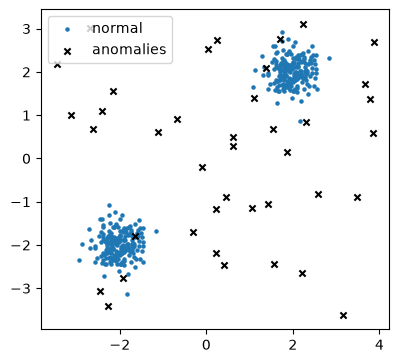

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import average_precision_score, precision_score, recall_score

# 400 normal points in two groups, 40 anomalies drawn in [-4, 4]²
rng = np.random.default_rng(0)
cluster = 0.3 * rng.standard_normal((200, 2))
X_normal = np.r_[cluster + 2, cluster - 2]
X_anomalies = rng.uniform(-4, 4, size=(40, 2))
X = np.r_[X_normal, X_anomalies]
is_anomaly = np.r_[np.zeros(len(X_normal), bool), np.ones(len(X_anomalies), bool)]


def report(title, predicted, score):
  """Points declared anomalous, precision and recall on the anomaly class."""
  print(f"{title}: {predicted.sum()} points declared anomalous")
  print(f"  precision {precision_score(is_anomaly, predicted):.2f}", end="")
  print(f", recall {recall_score(is_anomaly, predicted):.2f}", end="")
  print(
    f", area under the precision-recall curve {average_precision_score(is_anomaly, score):.2f}"
  )


def show_errors(ax, predicted):
  """The points, with the detection errors circled."""
  false_pos = predicted & ~is_anomaly
  false_neg = ~predicted & is_anomaly
  ax.scatter(*X_normal.T, s=5, color="C0", label="normal")
  ax.scatter(*X_anomalies.T, s=20, marker="x", color="k", label="anomalies")
  ax.scatter(
    *X[false_pos].T,
    s=80,
    facecolors="none",
    edgecolors="C1",
    lw=1.5,
    label=f"false positives ({false_pos.sum()})",
  )
  ax.scatter(
    *X[false_neg].T,
    s=80,
    marker="s",
    facecolors="none",
    edgecolors="C3",
    lw=1.5,
    label=f"false negatives ({false_neg.sum()})",
  )
  ax.set_xlim(-5, 5)
  ax.set_ylim(-5, 5)
  ax.set_aspect("equal")


fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.scatter(*X_normal.T, s=5, color="C0", label="normal")
ax.scatter(*X_anomalies.T, s=20, marker="x", color="k", label="anomalies")
ax.set_aspect("equal")
ax.legend(loc="upper left")
plt.show()

## 5 and 35 Neighbors

The anomaly score is the LOF itself (`-negative_outlier_factor_`). The threshold is the Isolation Forest demonstration's: `contamination` is the true share of anomalies, 40 out of 440, so the LOF declares 40 points anomalous.

In [3]:
from sklearn.neighbors import LocalOutlierFactor

contamination = len(X_anomalies) / len(X)  # 40 / 440
results = {}
for n_neighbors in (5, 35):
  lof = LocalOutlierFactor(n_neighbors=n_neighbors, contamination=contamination)
  predicted = lof.fit_predict(X) == -1
  # the LOF: ≈ 1 for a normal point, ≫ 1 for an anomaly
  score = -lof.negative_outlier_factor_
  report(f"n_neighbors = {n_neighbors}", predicted, score)
  results[n_neighbors] = predicted, score

n_neighbors = 5: 40 points declared anomalous
  precision 0.42, recall 0.42, area under the precision-recall curve 0.42
n_neighbors = 35: 40 points declared anomalous
  precision 0.90, recall 0.90, area under the precision-recall curve 0.95


Around each point, a circle all the larger as its LOF exceeds 1; the errors are circled:

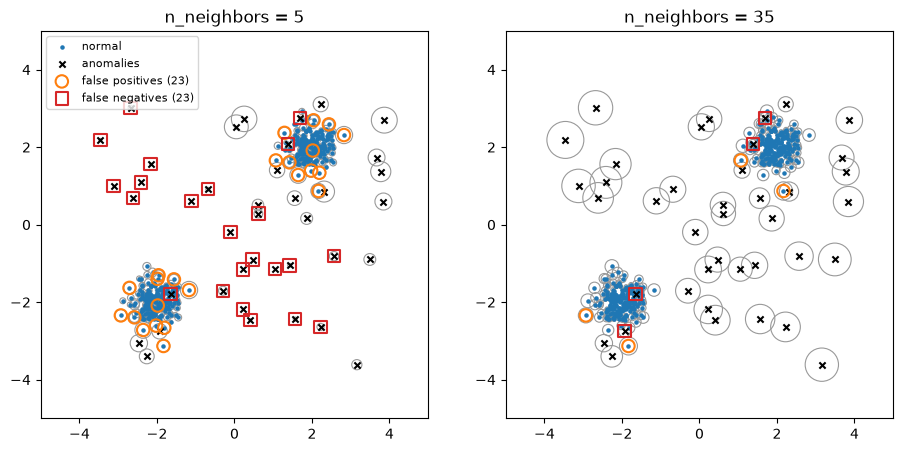

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
for ax, (n_neighbors, (predicted, score)) in zip(axes, results.items()):
  # One circle per point, its area proportional to LOF - 1 (same scale on both plots)
  ax.scatter(*X.T, s=100 * (score - 1).clip(0), fc="none", ec="0.6", lw=0.8)
  show_errors(ax, predicted)
  ax.set_title(f"n_neighbors = {n_neighbors}")
axes[0].legend(loc="upper left", fontsize=8)
plt.show()

With 5 neighbors, the neighbors of an isolated anomaly are other anomalies, just as sparse: the same density as its neighbors, LOF ≈ 1, it looks normal. Almost every anomaly far from the groups is missed, and small density variations inside the groups get normal points declared anomalous there. Precision, recall and area under the precision-recall curve fall to 0.42.

With 35 neighbors, the neighborhood of an anomaly reaches a dense group: its density is much lower than its neighbors', LOF ≫ 1. Precision and recall rise to 0.90, like Isolation Forest on the same data (area under the precision-recall curve 0.95, against 0.94). With 5 neighbors, it was the introduction's "too small".